
# makemore: part 3

In [78]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
import time
import numpy as np


In [79]:

# from datasets import load_dataset
# import json
# import re
# import unicodedata

# DATASET_NAME = "OpenLLM-France/Claire-Dialogue-French-0.1"
# # Login using e.g. `huggingface-cli login` to access this dataset
# ds = load_dataset(DATASET_NAME);

# split = 'train'
# dataset = load_dataset(DATASET_NAME, split=split)

# print(len(ds.data))
# print(ds.data.keys())

# # split into shards to be loaded into memory
# shards = []
# shard_size = 1000
# for i in range(0, len(dataset), shard_size):
#     shards.append(dataset[i:i+shard_size])
# dialogues = [el['text'] for el in ds['train']]

# # Refomating
# to_remove_c = "µ"
# dialogues = [el.replace(to_remove_c, "") for el in dialogues]
# dialogues = [re.sub(r'\[.*?\] ', '', el) for el in dialogues]
# dialogues = [unicodedata.normalize('NFKD', el).encode('ascii', 'ignore').decode('utf-8') for el in dialogues]

# print(dialogues[0][:100])
# print(len(dialogues), "dialogues")


# start_word = 0
# #### SPLITS
# for i in range (1000):
#     if sum(len(w) + 1 for w in dialogues[start_word:start_word+i]) > 2000_000:
#         words = dialogues[start_word:start_word+i]
#         print( i,"cut at", i + start_word, "dialogues with ", sum(len(w) + 1 for w in words), "characters")
#         start_word += i
#         break



In [95]:

import random
### build the dataset
block_size = 10
T = 100
end_char = '_' 
batch_size = 32

if True: # read in all the words
    with open("data/names.txt", "r") as f:
        words = f.readlines()
    words = [word.strip() for word in words]
    #random.seed(42)
    random.shuffle(words)
    if end_char in "".join(words): exit(f"the character '{end_char}' is already in the vocabulary")
    text = end_char.join(words)


# here are all the unique characters that occur in this text
chars = sorted(list(set(text)))
vocab_size = len(chars)
# create a mapping from characters to integers
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode = lambda s: [stoi[c] for c in s] # encoder: take a string, output a list of integers
decode = lambda l: ''.join([itos[i] for i in l]) # decoder: take a list of integers, output a string



class DataLoader:
    def __init__(self, data, block_size, T, batch_size=32):
        self.data = data
        self.block_size = block_size
        self.T = T
        self.B = batch_size
        self.reset()
        self.easy_mode = False

    def reset(self):
        #self.batch_indices = torch.randint(1, len(self.data) - self.T - 100, (self.batch_size,))
        self.batch_reset = True
        self.index = random.randint(0, self.T)

    def get_batch(self):
        buf = self.data[self.index : self.index+self.B*self.T+1]
        x = (buf[:-1]).view(self.B, self.T) # inputs
        y = (buf[1:]).view(self.B, self.T) # targets

        # x = torch.stack([self.data[idx:idx + self.T] for idx in self.batch_indices])  # Inputs
        # offset = -2 if self.easy_mode else 0
        # y = torch.stack([self.data[idx + self.T + offset] for idx in self.batch_indices])#[:, -1]  # Next token targets
        # self.batch_indices += 1
        # if (self.batch_indices >= len(self.data) - self.T).any():
        #     self.reset()
        self.index += self.B * self.T
        if self.index + self.B * self.T + 1 > len(self.data):
            self.reset()
        return x, y



# Train and test splits
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9*len(data)) # first 90% will be train, rest val
DLtr = DataLoader(data[:n], block_size=block_size, T=T, batch_size=batch_size)
DLte = DataLoader(data[n:], block_size=block_size, T=T, batch_size=batch_size)
print(f"training_data {n} : {n//batch_size} Time learning - {n//(batch_size * T)} batches")

# show first 5 examples
xb, yb = DLtr.get_batch()
print(decode(xb[0].tolist()), decode(yb[0].tolist()))
for i in range(15,20):
    x = xb[:, i:i+block_size]
    y = yb[:, i+block_size - 1]
    for b in range(2):
        print("X", i, ":", decode(x[b].tolist()), '-->', decode([y[b].tolist()]), end = "      \t\t")
    print()

for i in range(100):
    x, y = DLtr.get_batch()
    #print("X", i, ":", decode(x[0].tolist()), '-->', decode([y[0].tolist()]))
    assert x.shape == (batch_size,T), x.shape 
    assert y.shape == (batch_size,T), "mlkjqmlkdjf"
    assert (0 <= x).all() and  (x < vocab_size).all()
    assert (0 <= y).all() and (y < vocab_size).all()


DLtr.reset()


training_data 205330 : 6416 Time learning - 64 batches
rius_breylon_keilyn_khabib_laveya_triniti_abdulahad_braylynn_lavina_chimdiebube_demonta_quantavius_a ius_breylon_keilyn_khabib_laveya_triniti_abdulahad_braylynn_lavina_chimdiebube_demonta_quantavius_an
X 15 : ilyn_khabi --> b      		X 15 : annaleya_l --> e      		
X 16 : lyn_khabib --> _      		X 16 : nnaleya_le --> a      		
X 17 : yn_khabib_ --> l      		X 17 : naleya_lea --> n      		
X 18 : n_khabib_l --> a      		X 18 : aleya_lean --> n      		
X 19 : _khabib_la --> v      		X 19 : leya_leann --> y      		


## loss log

### original:
train 2.1245384216308594
val   2.168196439743042

### fix softmax confidently wrong:
train 2.07
val   2.13

### fix tanh layer too saturated at init:
train 2.0355966091156006
val   2.1026785373687744

### use semi-principled "kaiming init" instead of hacky init:
train 2.0376641750335693
val   2.106989622116089

### add batch norm layer
train 2.0668270587921143
val 2.104844808578491


In [81]:
# PYTORCHIFYING -----------
class Linear:
  
  def __init__(self, fan_in, fan_out, bias=True):
    # kaiming initialization : 
    self.weight = torch.randn((fan_in, fan_out)) * (2/(fan_in+fan_out)) 
    self.bias = torch.zeros(fan_out) if bias else None
  
  def __call__(self, x):
    self.out = x @ self.weight
    if self.bias is not None:
      self.out += self.bias
    return self.out
  
  def parameters(self):
    return [self.weight] + ([] if self.bias is None else [self.bias])

# -----------------------------------------------------------------------------------------------

class BatchNorm1d:
  
  def __init__(self, dim, eps=1e-5, momentum=0.1):
    self.eps = eps
    self.momentum = momentum
    self.training = True
    # parameters (trained with backprop)
    self.gamma = torch.ones(dim)
    self.beta = torch.zeros(dim)
    # buffers (trained with a running 'momentum update')
    self.running_mean = torch.zeros(dim)
    self.running_var = torch.ones(dim)
  
  def __call__(self, x):
    # calculate the forward pass
    if self.training:
      xmean = x.mean(0, keepdim=True) # batch mean
      xvar = x.var(0, keepdim=True) # batch variance
    else:
      xmean = self.running_mean
      xvar = self.running_var
    xhat = (x - xmean) / torch.sqrt(xvar + self.eps) # normalize to unit variance
    self.out = self.gamma * xhat + self.beta
    # update the buffers
    if self.training:
      with torch.no_grad():
        self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
        self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
    return self.out
  
  def parameters(self):
    return [self.gamma, self.beta]
  
# -----------------------------------------------------------------------------------------------

class Tanh:
  def __call__(self, x):
    self.out = torch.tanh(x)
    return self.out
  def parameters(self):
    return []
  
# -----------------------------------------------------------------------------------------------

class Embedding: # for each vocab index, look up the corresponding vector in a table
  def __init__(self, num_embeddings, embedding_dim):
    self.weight = torch.randn((num_embeddings, embedding_dim))
    
  def __call__(self, IX):
    self.out = self.weight[IX]
    return self.out
  
  def parameters(self):
    return [self.weight]

# -----------------------------------------------------------------------------------------------

class Flatten: 
    def __call__(self, x):
        self.out = x.view(x.shape[0], -1)
        return self.out
    def parameters(self):
        return []
    
# -----------------------------------------------------------------------------------------------

class Sequential:
  def __init__(self, layers):
    self.layers = layers
  
  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    self.out = x
    return self.out
  
  def parameters(self):
    # get parameters of all layers and stretch them out into one list
    return [p for layer in self.layers for p in layer.parameters()]


In [132]:
# Let's train a deeper network
# The classes we create here are the same API as nn.Module in PyTorch
  
n_embd = 20 # the dimensionality of the character embedding vectors
n_hidden = 128 # the number of neurons in the hidden layer of the MLP

torch.manual_seed(42)


model = Sequential([
  Embedding(vocab_size, n_embd), Flatten(),
  Linear(n_embd * block_size, n_hidden, bias=True), Tanh(),
  Linear(n_hidden, n_hidden, bias=True), Tanh(),
  Linear(n_hidden, n_hidden, bias=True), Tanh(),
  Linear(n_hidden, vocab_size)
])


with torch.no_grad():
  # last layer: make less confident
  model.layers[-1].weight *= 0.1
  model.layers[-1].bias *= 0.1
  # all other layers: apply gain
  for layer in model.layers[:-1]:
    if isinstance(layer, Linear):
      layer.weight *= 0.5 #* 5/3

parameters = model.parameters()
print(sum(p.nelement() for p in parameters)) # number of parameters in total
print(f"Parameters by layer :\n" + "\n".join([f"{sum(p.nelement() for p in layer.parameters())}\t   {layer.__class__.__name__} \t  {[tuple(p.shape) for p in layer.parameters()]}" for layer in model.layers]))
   
for p in parameters:
    p.requires_grad = True

###
train_index = 0
total_steps = 0
train_time = 0
batch_size = 32
lossi = [] # store loss values
ud = [] # store updates

62775
Parameters by layer :
540	   Embedding 	  [(27, 20)]
0	   Flatten 	  []
25728	   Linear 	  [(200, 128), (128,)]
0	   Tanh 	  []
16512	   Linear 	  [(128, 128), (128,)]
0	   Tanh 	  []
16512	   Linear 	  [(128, 128), (128,)]
0	   Tanh 	  []
3483	   Linear 	  [(128, 27), (27,)]


In [ ]:
# same optimization as last time
steps = 50_000
total_steps += steps

start_time = time.time()


for layer in model.layers:
    layer.training = True

index = 0
Xbt, Ybt = DLtr.get_batch()
for i in range(steps):
    #Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
    
    Xb = Xbt[:, index:index + block_size]
    Yb = Ybt[:, index + block_size - 1]
    index += 1
    if index + block_size > T:
        index = 0
        Xbt, Ybt = DLtr.get_batch()
    

    # forward pass
    x = model(Xb) # forward pass
    loss = F.cross_entropy(x, Yb) # loss function
    
    # retain grad for tanh
    for layer in model.layers:
        layer.out.retain_grad()

    # backward pass
    for p in parameters:
        p.grad = None # zero all the gradients in the model
    loss.backward() # calculate the gradients
    
    # update
    lr = 0.0010 if train_index < 150000 else 0.008 # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    lossi.append(loss.log10().item())
    if i % (steps//10) == 0: # print every once in a while
        average_loss = sum(lossi[-(steps//10):])/len(lossi[-(steps//10):])
        print(f'{train_index:7d}/{total_steps:7d}:  {average_loss:.4f} - {10*average_loss:.4f}  ({train_time + time.time() - start_time:.0f} seconds)')
    with torch.no_grad():
        ud.append([((lr*p.grad).std() / p.data.std()).log10().item() for p in parameters])
    
    train_index += 1
    #if i >= 2000 - 1: break # AFTER_DEBUG: would take out obviously to run full optimization
train_time += time.time() - start_time
print(f"Training time: {train_time:.0f} seconds")

for layer in model.layers:
    layer.training = False

  40000/  90000:  0.4504 - 4.5038  (34 seconds)
  45000/  90000:  0.4503 - 4.5033  (38 seconds)
  50000/  90000:  0.4502 - 4.5019  (41 seconds)
  55000/  90000:  0.4502 - 4.5021  (45 seconds)
  60000/  90000:  0.4506 - 4.5058  (49 seconds)
  65000/  90000:  0.4502 - 4.5016  (52 seconds)
  70000/  90000:  0.4503 - 4.5027  (56 seconds)
  75000/  90000:  0.4502 - 4.5022  (59 seconds)
  80000/  90000:  0.4504 - 4.5036  (62 seconds)
  85000/  90000:  0.4500 - 4.4996  (66 seconds)
Training time: 70 seconds


# 90000 steps, 70s (Batch: 32, block: 10, lr: 0.001, hidden: 128) : 2.825282621383667
 train loss : 2.8031   	 acc 15.9% 	 prob 7.9%     (log:0.4476345560704081)
test  loss : 2.8253  	 acc 15.2% 	 prob 7.9%
Overfitting : 0.02220866680145228


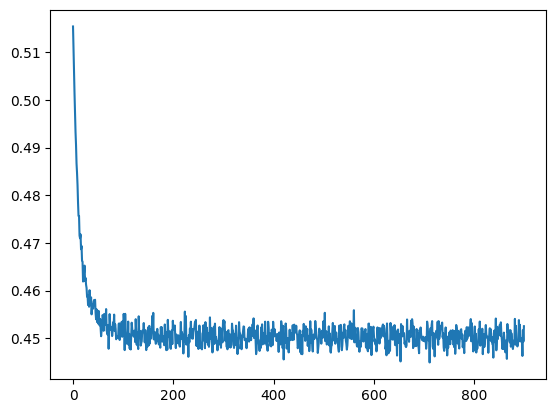

In [ ]:
#  Evaluate the model
@torch.no_grad()  # Disable gradient tracking
def split_loss_and_accuracy(DL, n_iteration=30):
    avg_loss = 0
    correct_predictions = 0
    total_predictions = 0
    avg_correct_prob = 0
    
    index = 0
    Xbt, Ybt = DL.get_batch()  # Fetch data batch
    for i in range(n_iteration):
        # Get the input and target sequences
        x = Xbt[:, index:index + block_size]
        y = Ybt[:, index]
        index += 1
        if index + block_size + 1 > T:
            index = 0
        
        # Forward pass through the model
        x = model(x)  # Output logits
        x = x.view(-1, vocab_size)  # Reshape logits for loss computation
        y = y.view(-1)  # Flatten targets

        #x = F.one_hot(y, vocab_size)

        # Compute loss
        avg_loss += F.cross_entropy(x, y, reduction='mean').item()

        # Compute accuracy
        predictions = torch.argmax(x, dim=1)  # Predicted class indices
        correct_predictions += (predictions == y).sum().item()  # Count correct predictions
        total_predictions += y.size(0)  # Count total predictions
        
        proba = F.softmax(x, dim=1)
        correct_probs = proba[torch.arange(y.size(0)), y]  # Correct class probabilities
        avg_correct_prob += correct_probs.mean().item()

    avg_loss /= n_iteration  # Average the loss over iterations
    accuracy = correct_predictions / total_predictions  # Compute accuracy
    avg_correct_prob /= n_iteration
    
    return avg_loss, accuracy, avg_correct_prob

DLtr.reset()
trl, tracc, tr_prob = split_loss_and_accuracy(DLtr)

test, teacc, te_prob = split_loss_and_accuracy(DLte)

print(f"# {total_steps} steps, {train_time:.0f}s (Batch: {batch_size}, block: {block_size}, lr: {lr}, hidden: {n_hidden}) : {test}")
print(f" train loss : {trl:.4f}   \t acc {tracc * 100:.1f}% \t prob {tr_prob * 100:.1f}%     (log:{np.log10(trl)})")
print(f"test  loss : {test:0.4f}  \t acc {teacc * 100:.1f}% \t prob {te_prob * 100:.1f}%")


print(f"Overfitting : {test - trl}")
if test - trl > 0.1:
    print("\033[91mModel is overfitting\033[0m")

spliter = 10**int(np.log10(len(lossi))-2)

plt.plot(torch.tensor(lossi).view(-1, spliter).mean(1));
#  train loss : 3.9451   	 acc 10.3%     (log:0.5960560473958015)   
#  test  loss : 3.9188  	 acc 8.4%


In [164]:
# sample from the model

g = torch.Generator().manual_seed(2147483647 + 10)

def generate_from(model, x, max_tokens=100):
    for i in range(max_tokens):
        inp = x[:,i:i+block_size]
        
        y = model(inp).view(-1, vocab_size)
        
        if i+block_size+1 >= x.shape[1]:
            probs = F.softmax(y, dim=1)
            ix = torch.multinomial(probs, num_samples=1, generator=g)
            x = torch.cat([x, ix], dim = 1)
    return x

x = DLte.get_batch()[0][:, :block_size]
# rius_breylon_keilyn_khabib_laveya_triniti_abdulahad_braylynn_lavina_chimdiebube_demonta_quantavius_a ius_breylon_keilyn_khabib_laveya_triniti_abdulahad_braylynn_lavina_chimdiebube_demonta_quantavius_an

x = torch.asarray([encode("_breylon_keilyn_") for _ in range(batch_size)])

out = generate_from(model, x)

for txt in out[:10]:
    txt = txt.tolist()
    print(decode(txt).replace(end_char, " ")[:50])

 breylon keilyn nsaseaan clliy lnrklnmaabnsarhoair
 breylon keilyn as  eeiii  nya ialar iumtn rit   f
 breylon keilyn rncln rrd kiadi wllnla a oaasorjiz
 breylon keilyn meeiior  ayndlea yaorhtdiaddshn dn
 breylon keilyn ajalryeoea eyt vmukit ebi yoeenueh
 breylon keilyn hrierann uazi ndjieiyzaetalaal aar
 breylon keilyn x iaarekun seh hnlieae m  e  ieaba
 breylon keilyn ahv i elinyslkr j ialna  akaarnnae
 breylon keilyn an   kphtll  tyvheheziszfia dnkna 
 breylon keilyn eeeaes amntaaond ak iuiosia ahaiin


(32, 128)
layer 3 (Tanh      ): mean -0.06, std 0.72, saturated: 0.00%


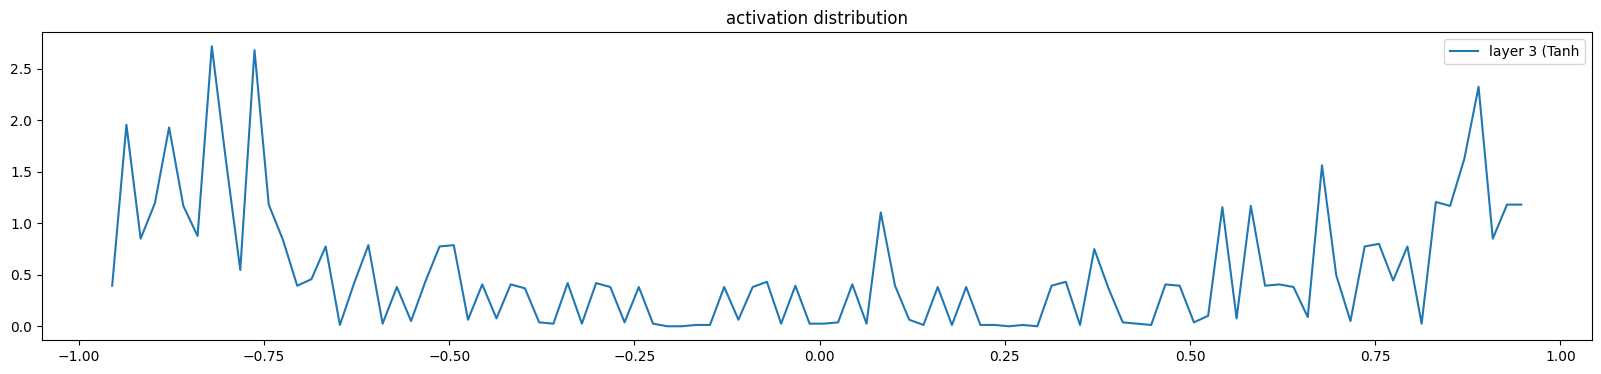

layer 0 (Embedding): no gradients
layer 2 (Linear): no gradients
layer 3 (Tanh): no gradients


/var/folders/_s/ysm78cds61z2q1t03gj_hj7w0000gn/T/ipykernel_75825/651556553.py:26: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more informations. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/build/aten/src/ATen/core/TensorBody.h:494.)
  t = layer.out.grad


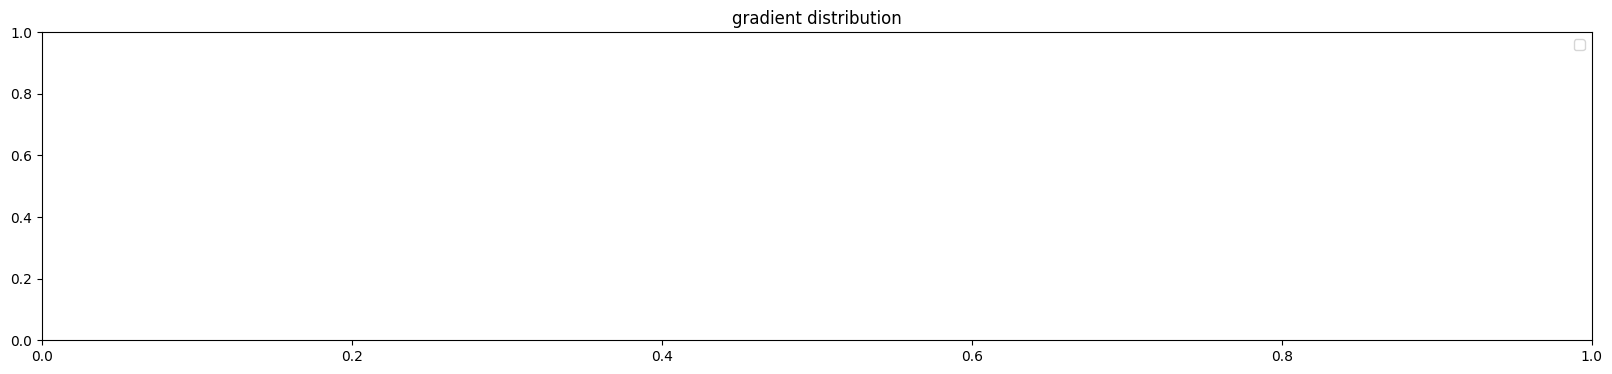

layer 2 (Linear): mean +0.00, std 0.00, grad:data ratio 0.00
layer 4 (Linear): mean -0.00, std 0.00, grad:data ratio 0.00


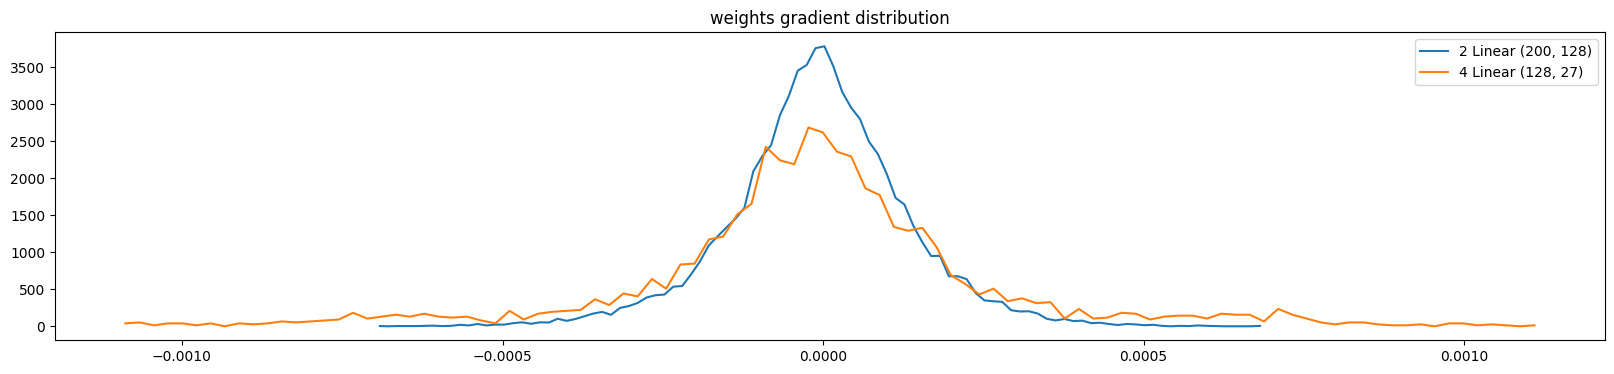

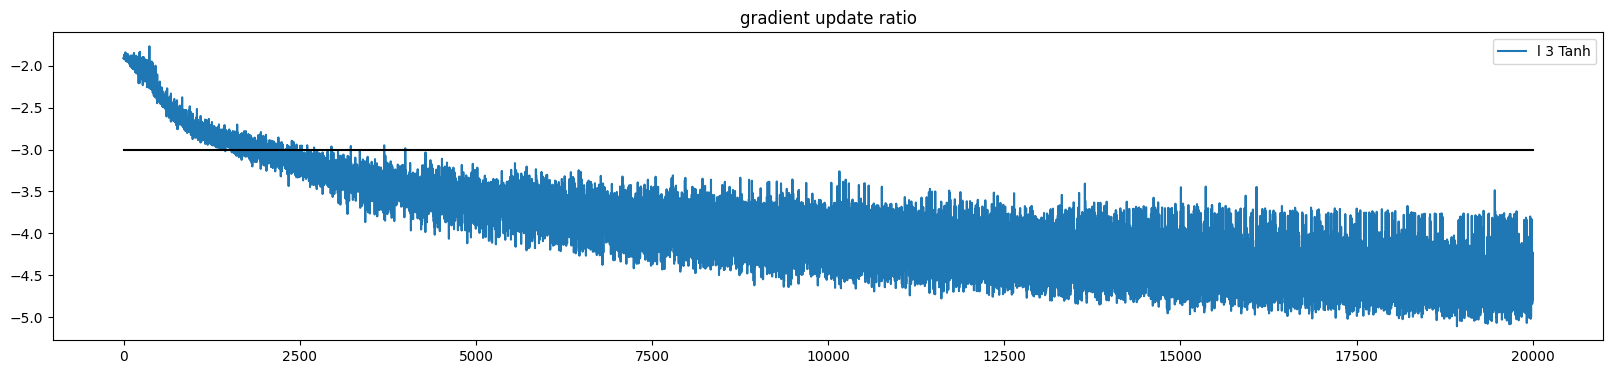

In [92]:
###### Activation distribution
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(model.layers[:-1]): # note: exclude the output layer
    if not isinstance(layer, Tanh): continue
    if isinstance(layer, Flatten): continue
    t = layer.out
    print(tuple(t.shape))
    print(f'layer {i} ({layer.__class__.__name__:10s}): mean {t.mean():+.2f}, std {t.std():.2f}, saturated: {(t.abs() > 0.97).float().mean()*100:.2f}%')
    if isinstance(layer, Tanh) and (t.abs() > 0.97).float().mean() > 0.10:
        print('\033[1;31m' + 'WARNING: ACTIVATIONS ARE SATURATING' + '\033[0m' + '\n You should : \n 1. decrease the learning rate \n 2. increase the batch size')
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('activation distribution');
plt.show()


###### Gradient distribution : this is the same as the activation distribution, but for the gradients
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(model.layers[:-1]): # note: exclude the output layer
    #if not isinstance(layer, Tanh): continue
    if isinstance(layer, Flatten): continue
    t = layer.out.grad
    if t is None:
        print(f'layer {i} ({layer.__class__.__name__}): no gradients')
        continue
    print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
    # torch histogram returns the density of the data ov
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('gradient distribution');
plt.show()


###### Weight distribution ######
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []

for i, layer in enumerate(model.layers):
    for p in layer.parameters():
        if p.ndim != 2 or not isinstance(layer, Linear): continue
        t = p.grad
        print(f'layer {i} ({layer.__class__.__name__}): mean {t.mean():+.2f}, std {t.std():.2f}, grad:data ratio {t.std() / layer.weight.std():.2f}')
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'{i} {layer.__class__.__name__} {tuple(p.shape)}')
   
plt.legend(legends)
plt.title('weights gradient distribution');
plt.show()


### Gradient update ratio
plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(model.layers[:-1]):
    if not isinstance(layer, Tanh): continue
    plt.plot([ud[j][i] for j in range(len(ud))])
    legends.append(f'l {i} {layer.__class__.__name__}')
plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);
plt.title('gradient update ratio');
plt.show()

In [ ]:
# DONE; BONUS content below, not covered in video

### BatchNorm forward pass as a widget

from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets
import scipy.stats as stats
import numpy as np


def normshow(x0):
    
    g = torch.Generator().manual_seed(2147483647+1)
    x = torch.randn(5, generator=g) * 5
    x[0] = x0 # override the 0th example with the slider
    mu = x.mean()
    sig = x.std()
    y = (x - mu)/sig

    plt.figure(figsize=(10, 5))
    # plot 0
    plt.plot([-6,6], [0,0], 'k')
    # plot the mean and std
    xx = np.linspace(-6, 6, 100)
    plt.plot(xx, stats.norm.pdf(xx, mu, sig), 'b')
    xx = np.linspace(-6, 6, 100)
    plt.plot(xx, stats.norm.pdf(xx, 0, 1), 'r')
    # plot little lines connecting input and output
    for i in range(len(x)):
        plt.plot([x[i],y[i]], [1, 0], 'k', alpha=0.2)
    # plot the input and output values
    plt.scatter(x.data, torch.ones_like(x).data, c='b', s=100)
    plt.scatter(y.data, torch.zeros_like(y).data, c='r', s=100)
    plt.xlim(-6, 6)
    # title
    plt.title('input mu %.2f std %.2f' % (mu, sig))

interact(normshow, x0=(-30,30,0.5));


interactive(children=(FloatSlider(value=0.0, description='x0', max=30.0, min=-30.0, step=0.5), Output()), _dom…

In [88]:
# Linear: activation statistics of forward and backward pass

g = torch.Generator().manual_seed(2147483647)

a = torch.randn((1000,1), requires_grad=True, generator=g)          # a.grad = b.T @ c.grad
b = torch.randn((1000,1000), requires_grad=True, generator=g)       # b.grad = c.grad @ a.T
c = b @ a
loss = torch.randn(1000, generator=g) @ c
a.retain_grad()
b.retain_grad()
c.retain_grad()
loss.backward()
print('a std:', a.std().item())
print('b std:', b.std().item())
print('c std:', c.std().item())
print('-----')
print('c grad std:', c.grad.std().item())
print('a grad std:', a.grad.std().item())
print('b grad std:', b.grad.std().item())

a std: 0.9875972270965576
b std: 1.0006722211837769
c std: 31.01241683959961
-----
c grad std: 0.9782556295394897
a grad std: 30.8818302154541
b grad std: 0.9666601419448853


In [89]:
# Linear + BatchNorm: activation statistics of forward and backward pass

g = torch.Generator().manual_seed(2147483647)

n = 1000
# linear layer ---
inp = torch.randn(n, requires_grad=True, generator=g)
w = torch.randn((n, n), requires_grad=True, generator=g) # / n**0.5
x = w @ inp
# bn layer ---
xmean = x.mean()
xvar = x.var()
out = (x - xmean) / torch.sqrt(xvar + 1e-5)
# ----
loss = out @ torch.randn(n, generator=g)
inp.retain_grad()
x.retain_grad()
w.retain_grad()
out.retain_grad()
loss.backward()

print('inp std: ', inp.std().item())
print('w std: ', w.std().item())
print('x std: ', x.std().item())
print('out std: ', out.std().item())
print('------')
print('out grad std: ', out.grad.std().item())
print('x grad std: ', x.grad.std().item())
print('w grad std: ', w.grad.std().item())
print('inp grad std: ', inp.grad.std().item())

inp std:  0.9875972270965576
w std:  1.0006722211837769
x std:  31.01241683959961
out std:  1.0
------
out grad std:  0.9782556295394897
x grad std:  0.031543977558612823
w grad std:  0.031169468536973
inp grad std:  0.9953053593635559
